# 3 · Comparing the six methods

Six ways of handling imbalance, each with 5 seeds, at 3 imbalance levels, on 2 model sizes (180 runs). Everything is scored once on the untouched test split.

| Method | What it does |
|---|---|
| Baseline | nothing: train on the imbalanced data |
| Class-weighted | weight the loss by inverse class frequency |
| Oversampling | repeat real minority images up to 874 per class (augmentation makes repeats differ) |
| GAN S1 / S2 / S3 | add generated images (see notebook 2) |

**Decision rule, fixed in advance:** a GAN scenario *works* only if its mean minority macro-F1 beats **each** of baseline, class-weighted and oversampling
by more than the larger seed standard deviation of the two methods compared.

In [1]:
%matplotlib inline
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import study
from study import metrics, LEVELS, METHODS, LABEL, COLOR
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "axes.axisbelow": True})
pd.set_option("display.width", 140)

## Primary measure: minority macro-F1 (main CNN, 5 seeds)

In [2]:
text, mean = study.table("minority_macro_f1", width="1")
text.columns = ["all real images", "100 per class", "30 per class"]
text

,all real images,100 per class,30 per class
Baseline,0.975 ± 0.016,0.949 ± 0.009,0.123 ± 0.117
Class-weighted,0.913 ± 0.025,0.873 ± 0.027,0.714 ± 0.028
Oversampling,0.989 ± 0.003,0.982 ± 0.005,0.966 ± 0.009
GAN S1,0.978 ± 0.009,0.944 ± 0.014,0.838 ± 0.036
GAN S2,0.982 ± 0.008,0.944 ± 0.011,0.742 ± 0.062
GAN S3,0.969 ± 0.009,0.960 ± 0.007,0.928 ± 0.019


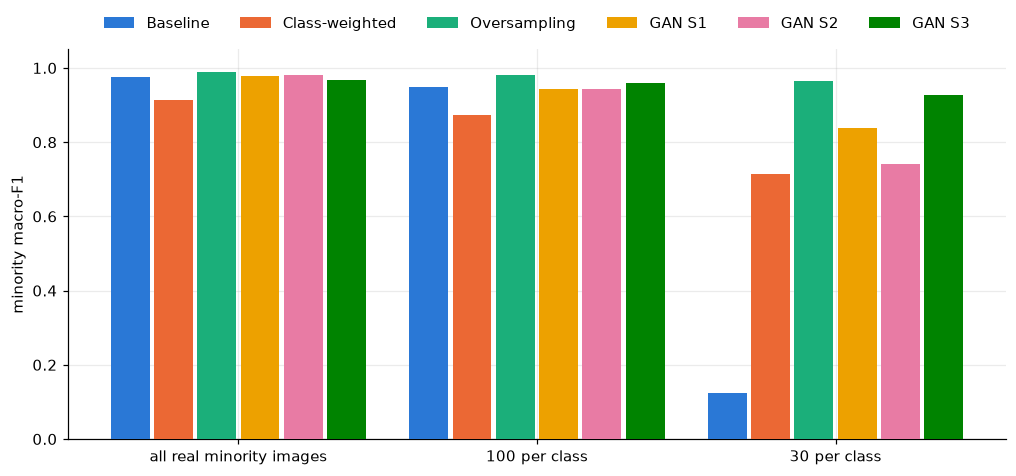

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.6))
w = .13
for mi, m in enumerate(METHODS):
    xs = np.arange(3) + (mi - 2.5) * (w + .015)
    ax.bar(xs, mean.loc[m].values, w, color=COLOR[m], label=LABEL[m], zorder=3)
ax.set_xticks(range(3)); ax.set_xticklabels(["all real minority images", "100 per class", "30 per class"])
ax.set_ylabel("minority macro-F1"); ax.set_ylim(0, 1.05)
ax.legend(ncol=6, frameon=False, loc="upper center", bbox_to_anchor=(.5, 1.12))
plt.show()

## Co-primary measure: macro-F1 over all 38 classes

Because the 31 other classes are plentiful, this measure moves much less. Imbalance mostly hurts the rare classes.

In [4]:
t2, _ = study.table("macro_f1", width="1")
t2.columns = ["all real images", "100 per class", "30 per class"]
t2

,all real images,100 per class,30 per class
Baseline,0.979 ± 0.004,0.975 ± 0.004,0.806 ± 0.018
Class-weighted,0.961 ± 0.007,0.950 ± 0.009,0.914 ± 0.011
Oversampling,0.986 ± 0.003,0.980 ± 0.004,0.977 ± 0.003
GAN S1,0.981 ± 0.003,0.974 ± 0.006,0.950 ± 0.010
GAN S2,0.982 ± 0.005,0.970 ± 0.007,0.923 ± 0.013
GAN S3,0.979 ± 0.005,0.977 ± 0.003,0.967 ± 0.005


## Accuracy hides the problem

At 30 real images per minority class the baseline's accuracy still looks excellent, while it has all but stopped recognising the minority classes.

In [5]:
rows = []
for m in METHODS:
    r = study.load_runs(m, "30")
    rows.append({"method": LABEL[m], "accuracy": np.mean([x["accuracy"] for x in r]),
                 "minority macro-F1": np.mean([x["minority_macro_f1"] for x in r])})
pd.DataFrame(rows).set_index("method").round(3)

,accuracy,minority macro-F1
method,,
Baseline,0.946,0.123
Class-weighted,0.940,0.714
Oversampling,0.984,0.966
GAN S1,0.974,0.838
GAN S2,0.964,0.742
GAN S3,0.979,0.928


## Does any GAN scenario pass the decision rule?

In [6]:
rows = []
for lv in LEVELS:
    s = study.summaries(lv)
    for g in metrics.GAN_SCENARIOS:
        ok, v = metrics.gan_works(s, gan=g)
        rows.append({"level": lv, "scenario": LABEL[g], "beats baseline": v["baseline"]["beats"],
                     "beats class-weighted": v["class_weighted"]["beats"], "beats oversampling": v["oversampling"]["beats"],
                     "margin vs oversampling": round(v["oversampling"]["margin"], 3), "WORKS": ok})
pd.DataFrame(rows)

,level,scenario,beats baseline,beats class-weighted,beats oversampling,margin vs oversampling,WORKS
0,full,GAN S1,False,True,False,-0.011,False
1,full,GAN S2,False,True,False,-0.007,False
2,full,GAN S3,False,True,False,-0.020,False
3,100,GAN S1,False,True,False,-0.038,False
4,100,GAN S2,False,True,False,-0.038,False
5,100,GAN S3,True,True,False,-0.021,False
6,30,GAN S1,True,True,False,-0.128,False
7,30,GAN S2,True,False,False,-0.223,False
8,30,GAN S3,True,True,False,-0.037,False


**No GAN scenario passes at any level.** Every one of them loses to plain oversampling, which is the decisive comparison.

## Same study on the quarter-width CNN (28k parameters)

A smaller model has less capacity to cope with imbalance on its own, so the gaps are bigger, but the ranking is the same.

In [7]:
t3, _ = study.table("minority_macro_f1", width="0.25")
t3.columns = ["all real images", "100 per class", "30 per class"]
t3

,all real images,100 per class,30 per class
Baseline,0.517 ± 0.049,0.001 ± 0.003,0.000 ± 0.000
Class-weighted,0.739 ± 0.029,0.603 ± 0.049,0.357 ± 0.036
Oversampling,0.856 ± 0.052,0.840 ± 0.004,0.850 ± 0.028
GAN S1,0.734 ± 0.040,0.615 ± 0.069,0.202 ± 0.096
GAN S2,0.654 ± 0.041,0.335 ± 0.038,0.070 ± 0.029
GAN S3,0.839 ± 0.024,0.776 ± 0.046,0.753 ± 0.044
